In [ ]:
Online Retail — PostgreSQL & SQL avancé
Projet portfolio : Customer & Sales Analytics
Stack : Python, pandas, SQLAlchemy, PostgreSQL, pgAdmin 4, Jupyter
Objectifs
1. Se connecter à PostgreSQL depuis Python.
2. Importer les ventes nettoyées dans une table SQL.
3. Vérifier la qualité et la cohérence des données.
4. Réaliser des analyses métier avec SQL : CTE, agrégations, fonctions de fenêtre et RFM

In [1]:
from pathlib import Path
from getpass import getpass

import pandas as pd
from sqlalchemy import create_engine, text
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "sales_clean.csv"

print("Dossier courant :", PROJECT_ROOT)
print("Fichier de données trouvé :", DATA_PATH.exists())


Dossier courant : c:\Users\yaraa\Downloads\customer-analytics-dashboard
Fichier de données trouvé : True


In [1]:
import sys
import psycopg2

print("Python :", sys.executable)
print("Psycopg2 :", psycopg2.__version__)
print("Module :", psycopg2.__file__)

Python : c:\Users\yaraa\Downloads\customer-analytics-dashboard\.venv\Scripts\python.exe
Psycopg2 : 2.9.13 (dt dec pq3 ext lo64)
Module : c:\Users\yaraa\Downloads\customer-analytics-dashboard\.venv\Lib\site-packages\psycopg2\__init__.py


In [ ]:
import os

os.environ["DB_PASSWORD"] = input("Entre ton mot de passe PostgreSQL : ")

In [3]:
DB_HOST = "localhost"
DB_PORT = "5432"
DB_NAME = "online_retail"
DB_USER = "postgres"
DB_PASSWORD = getpass("Mot de passe PostgreSQL : ")

DATABASE_URL = (
    f"postgresql+psycopg2://{DB_USER}:{DB_PASSWORD}"
    f"@{DB_HOST}:{DB_PORT}/{DB_NAME}"
)

engine = create_engine(DATABASE_URL)

with engine.connect() as connection:
    result = connection.execute(text("SELECT version();"))
    print(result.scalar())


PostgreSQL 19.0 on x86_64-windows, compiled by msvc-19.44.35230, 64-bit


Charger les données nettoyées
On importe le fichier transactionnel sales_clean.csv. Il contient une ligne par ligne de vente conservée après nettoyage.

In [4]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Fichier introuvable : {DATA_PATH}\n"
        "Vérifie le dossier data/processed."
    )

df = pd.read_csv(DATA_PATH, low_memory=False)
print("Dimensions :", df.shape)
display(df.head())
print(df.dtypes)


Dimensions : (524878, 13)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancellation,InvalidQuantity,InvalidPrice,InvalidDate,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom,False,False,False,False,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,False,False,False,False,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom,False,False,False,False,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,False,False,False,False,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,False,False,False,False,20.34


InvoiceNo              str
StockCode              str
Description            str
Quantity             int64
InvoiceDate            str
UnitPrice          float64
CustomerID         float64
Country                str
IsCancellation        bool
InvalidQuantity       bool
InvalidPrice          bool
InvalidDate           bool
Revenue            float64
dtype: object


Préparer les types avant l'import SQL
On harmonise les types les plus importants. Les noms de colonnes seront normalisés en minuscules avec underscores pour faciliter leur utilisation en SQL.

In [5]:
df.columns = (
    df.columns.str.strip()
              .str.lower()
              .str.replace(r"[^a-z0-9]+", "_", regex=True)
              .str.strip("_")
)

# Conversion prudente des dates et identifiants si les colonnes existent
if "invoicedate" in df.columns:
    df["invoicedate"] = pd.to_datetime(df["invoicedate"], errors="coerce")

if "customerid" in df.columns:
    df["customerid"] = pd.to_numeric(df["customerid"], errors="coerce").astype("Int64")

display(df.head())
print(df.dtypes)


,invoiceno,stockcode,description,quantity,invoicedate,unitprice,customerid,country,iscancellation,invalidquantity,invalidprice,invaliddate,revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,False,False,False,False,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,False,False,False,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,False,False,False,False,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,False,False,False,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,False,False,False,20.34


invoiceno                     str
stockcode                     str
description                   str
quantity                    int64
invoicedate        datetime64[us]
unitprice                 float64
customerid                  Int64
country                       str
iscancellation               bool
invalidquantity              bool
invalidprice                 bool
invaliddate                  bool
revenue                   float64
dtype: object


Importer dans PostgreSQL
Cette cellule crée ou remplace la table retail_sales. Pour un premier chargement, c'est pratique. Attention : if_exists="replace" supprime puis recrée la table à chaque exécution.

In [8]:
df.to_sql(
    name="retail_sales",
    con=engine,
    if_exists="replace",
    index=False,
    chunksize=2_000,
    method="multi"
)

print("Import terminé.")


Import terminé.


Vérifier l'import avec SQL
On vérifie le nombre de lignes, les dates et les principales statistiques. Les requêtes SQL seront exécutées depuis Python, mais tu pourras aussi les copier dans l'éditeur de requêtes pgAdmin.

In [9]:
with engine.connect() as connection:
    count_df = pd.read_sql_query(
        text("SELECT COUNT(*) AS row_count FROM retail_sales;"),
        connection
    )
display(count_df)


,row_count
0,524878


In [12]:
with engine.connect() as connection:
    result = connection.execute(
        text("SELECT * FROM retail_sales LIMIT 5;")
    )

    for row in result:
        print(row)

('536365', '85123A', 'WHITE HANGING HEART T-LIGHT HOLDER', 6, datetime.datetime(2010, 12, 1, 8, 26), 2.55, 17850, 'United Kingdom', False, False, False, False, 15.299999999999999)
('536365', '71053', 'WHITE METAL LANTERN', 6, datetime.datetime(2010, 12, 1, 8, 26), 3.39, 17850, 'United Kingdom', False, False, False, False, 20.34)
('536365', '84406B', 'CREAM CUPID HEARTS COAT HANGER', 8, datetime.datetime(2010, 12, 1, 8, 26), 2.75, 17850, 'United Kingdom', False, False, False, False, 22.0)
('536365', '84029G', 'KNITTED UNION FLAG HOT WATER BOTTLE', 6, datetime.datetime(2010, 12, 1, 8, 26), 3.39, 17850, 'United Kingdom', False, False, False, False, 20.34)
('536365', '84029E', 'RED WOOLLY HOTTIE WHITE HEART.', 6, datetime.datetime(2010, 12, 1, 8, 26), 3.39, 17850, 'United Kingdom', False, False, False, False, 20.34)


In [13]:
with engine.connect() as connection:
    result = connection.execute(text("""
        SELECT column_name, data_type
        FROM information_schema.columns
        WHERE table_name = 'retail_sales'
        ORDER BY ordinal_position;
    """))

    for row in result:
        print(row)

('invoiceno', 'text')
('stockcode', 'text')
('description', 'text')
('quantity', 'bigint')
('invoicedate', 'timestamp without time zone')
('unitprice', 'double precision')
('customerid', 'bigint')
('country', 'text')
('iscancellation', 'boolean')
('invalidquantity', 'boolean')
('invalidprice', 'boolean')
('invaliddate', 'boolean')
('revenue', 'double precision')


In [10]:
query_quality = """
SELECT
    COUNT(*) AS total_rows,
    COUNT(*) FILTER (WHERE customerid IS NULL) AS rows_without_customer,
    COUNT(DISTINCT invoiceno) AS distinct_invoices,
    MIN(invoicedate) AS first_invoice_date,
    MAX(invoicedate) AS last_invoice_date,
    ROUND(SUM(revenue)::numeric, 2) AS total_revenue
FROM retail_sales;
"""

with engine.connect() as connection:
    quality_df = pd.read_sql_query(text(query_quality), connection)
display(quality_df)


,total_rows,rows_without_customer,distinct_invoices,first_invoice_date,last_invoice_date,total_revenue
0,524878,132186,19960,2010-12-01 08:26:00,2011-12-09 12:50:00,"10,642,110.80"


Chiffre d'affaires mensuel
Notions : DATE_TRUNC, GROUP BY, agrégation.

,sales_month,monthly_revenue,number_of_orders
0,2010-12-01,"821,452.73",1559
1,2011-01-01,"689,811.61",1086
2,2011-02-01,"522,545.56",1100
3,2011-03-01,"716,215.26",1454
4,2011-04-01,"536,968.49",1246
5,2011-05-01,"769,296.61",1681
6,2011-06-01,"760,547.01",1533
7,2011-07-01,"718,076.12",1475
8,2011-08-01,"757,841.38",1361
9,2011-09-01,"1,056,435.19",1837


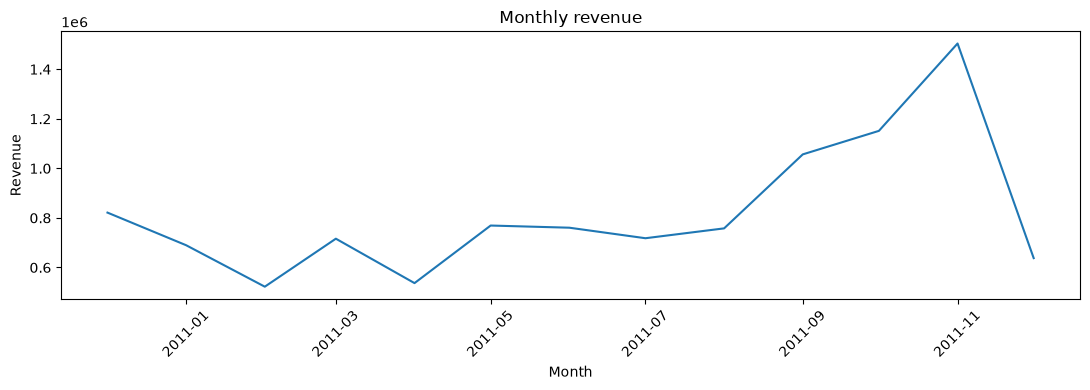

In [11]:
query_monthly = """
SELECT
    DATE_TRUNC('month', invoicedate)::date AS sales_month,
    ROUND(SUM(revenue)::numeric, 2) AS monthly_revenue,
    COUNT(DISTINCT invoiceno) AS number_of_orders
FROM retail_sales
GROUP BY 1
ORDER BY 1;
"""

with engine.connect() as connection:
    monthly_df = pd.read_sql_query(text(query_monthly), connection)

display(monthly_df)
monthly_df.plot(x="sales_month", y="monthly_revenue", figsize=(11, 4), legend=False)
plt.title("Monthly revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [23]:
query_top_products = """
SELECT
    stockcode,
    MAX(description) AS product_description,
    ROUND(SUM(revenue)::numeric, 2) AS total_revenue,
    SUM(quantity) AS units_sold
FROM retail_sales
WHERE TRIM(stockcode) ~ '^[0-9]{5}[A-Za-z]?$'
GROUP BY stockcode
ORDER BY total_revenue DESC
LIMIT 10;
"""

with engine.connect() as connection:
    top_products_df = pd.read_sql_query(text(query_top_products), connection)
display(top_products_df)


,stockcode,product_description,total_revenue,units_sold
0,22423,REGENCY CAKESTAND 3 TIER,"174,156.54","13,851.00"
1,23843,"PAPER CRAFT , LITTLE BIRDIE","168,469.60","80,995.00"
2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"104,462.75","37,641.00"
3,47566,PARTY BUNTING,"99,445.23","18,283.00"
4,85099B,JUMBO BAG RED RETROSPOT,"94,159.81","48,371.00"
5,23166,MEDIUM CERAMIC TOP STORAGE JAR,"81,700.92","78,033.00"
6,23084,RABBIT NIGHT LIGHT,"66,870.03","30,739.00"
7,22086,PAPER CHAIN KIT 50'S CHRISTMAS,"64,875.59","19,329.00"
8,84879,ASSORTED COLOUR BIRD ORNAMENT,"58,927.62","36,362.00"
9,79321,CHILLI LIGHTS,"54,096.36","10,302.00"


Segmentation RFM en SQL
Notions : CTE (WITH), agrégations conditionnelles, calcul de récence.

La date de référence est fixée au lendemain de la dernière date disponible dans le dataset. Les clients anonymes sont exclus de la segmentation.

In [24]:
query_rfm = """
WITH reference_date AS (
    SELECT MAX(invoicedate)::date + INTERVAL '1 day' AS ref_date
    FROM retail_sales
),
customer_metrics AS (
    SELECT
        customerid,
        (SELECT ref_date FROM reference_date) - MAX(invoicedate)::date AS recency_days,
        COUNT(DISTINCT invoiceno) AS frequency,
        SUM(revenue) AS monetary
    FROM retail_sales
    WHERE customerid IS NOT NULL
    GROUP BY customerid
)
SELECT
    customerid,
    recency_days,
    frequency,
    ROUND(monetary::numeric, 2) AS monetary
FROM customer_metrics
ORDER BY monetary DESC;
"""

with engine.connect() as connection:
    rfm_df = pd.read_sql_query(text(query_rfm), connection)
display(rfm_df.head(10))


,customerid,recency_days,frequency,monetary
0,14646,2 days,73,"280,206.02"
1,18102,1 days,60,"259,657.30"
2,17450,9 days,46,"194,390.79"
3,16446,1 days,2,"168,472.50"
4,14911,2 days,201,"143,711.17"
5,12415,25 days,21,"124,914.53"
6,14156,10 days,55,"117,210.08"
7,17511,3 days,31,"91,062.38"
8,16029,39 days,63,"80,850.84"
9,12346,326 days,1,"77,183.60"


Classement des clients avec une fonction de fenêtre
Notions : DENSE_RANK() OVER, PARTITION BY, ORDER BY.

On classe les clients par chiffre d'affaires à l'intérieur de chaque pays

In [25]:
query_customer_rank = """
WITH customer_country_revenue AS (
    SELECT
        country,
        customerid,
        SUM(revenue) AS customer_revenue
    FROM retail_sales
    WHERE customerid IS NOT NULL
    GROUP BY country, customerid
)
SELECT
    country,
    customerid,
    ROUND(customer_revenue::numeric, 2) AS customer_revenue,
    DENSE_RANK() OVER (
        PARTITION BY country
        ORDER BY customer_revenue DESC
    ) AS revenue_rank
FROM customer_country_revenue
ORDER BY country, revenue_rank
LIMIT 100;
"""

with engine.connect() as connection:
    rank_df = pd.read_sql_query(text(query_customer_rank), connection)
display(rank_df)


,country,customerid,customer_revenue,revenue_rank
0,Australia,12415,"124,914.53",1
1,Australia,12431,"5,447.17",2
2,Australia,12388,"2,780.66",3
3,Australia,12424,"1,760.96",4
4,Australia,12393,"1,582.60",5
...,...,...,...,...
95,France,12731,"18,895.91",1
96,France,12678,"17,628.46",2
97,France,12681,"13,787.54",3
98,France,12536,"12,601.83",4


In [18]:
query_mom = """

WITH monthly AS (
    SELECT
        DATE_TRUNC('month', invoicedate)::date AS sales_month,
        SUM(revenue) AS revenue
    FROM retail_sales
    GROUP BY 1
),
with_previous AS (
    SELECT
        sales_month,
        revenue,
        LAG(revenue) OVER (ORDER BY sales_month) AS previous_month_revenue
    FROM monthly
)
SELECT
    sales_month,
    ROUND(revenue::numeric, 2) AS revenue,
    ROUND(previous_month_revenue::numeric, 2) AS previous_month_revenue,
    ROUND(
        (
            100.0 * (revenue - previous_month_revenue)
            / NULLIF(previous_month_revenue, 0)
        )::numeric,
        2
    ) AS month_over_month_pct
FROM with_previous
ORDER BY sales_month;
"""

with engine.connect() as connection:
    mom_df = pd.read_sql_query(text(query_mom), connection)
display(mom_df)


,sales_month,revenue,previous_month_revenue,month_over_month_pct
0,2010-12-01,"821,452.73",NaN,NaN
1,2011-01-01,"689,811.61","821,452.73",-16.03
2,2011-02-01,"522,545.56","689,811.61",-24.25
3,2011-03-01,"716,215.26","522,545.56",37.06
4,2011-04-01,"536,968.49","716,215.26",-25.03
5,2011-05-01,"769,296.61","536,968.49",43.27
6,2011-06-01,"760,547.01","769,296.61",-1.14
7,2011-07-01,"718,076.12","760,547.01",-5.58
8,2011-08-01,"757,841.38","718,076.12",5.54
9,2011-09-01,"1,056,435.19","757,841.38",39.40


Questions métier à résoudre
Essaie de répondre à ces questions en SQL avant de regarder des solutions plus complexes :
1. Quels sont les 10 clients qui génèrent le plus de chiffre d'affaires ?
2. Quel pays a le panier moyen par commande le plus élevé ?
3. Quels clients ont passé au moins 5 commandes ?
4. Pour chaque mois, quel est le produit numéro 1 en chiffre d'affaires ?
5. Quels clients n'ont pas commandé au cours des 90 derniers jours du dataset ?
6. Quelle part du chiffre d'affaires est générée par les 10 % de clients les plus importants ?
Pour chaque analyse, ajoute une courte interprétation métier : résultat, explication possible et limite éventuelle.

Exporter des résultats pour Power BI
Exemple : exporter les ventes mensuelles et les indicateurs RFM dans des CSV que Power BI pourra lire.

Avant l'export, vérifie que les résultats sont cohérents avec les analyses Python du projet.

In [26]:
EXPORT_DIR = PROJECT_ROOT / "data" / "processed" / "sql_exports"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

monthly_df.to_csv(EXPORT_DIR / "monthly_sales_sql.csv", index=False)
rfm_df.to_csv(EXPORT_DIR / "customer_rfm_sql.csv", index=False)
top_products_df.to_csv(EXPORT_DIR / "top_products_sql.csv", index=False)

print("Exports créés dans :", EXPORT_DIR)


Exports créés dans : c:\Users\yaraa\Downloads\customer-analytics-dashboard\data\processed\sql_exports


In [20]:
import matplotlib.pyplot as plt
import pandas as pd

# Préparer les données
mom_df["sales_month"] = pd.to_datetime(mom_df["sales_month"])

mom_df = mom_df.sort_values("sales_month")

print(mom_df.head())

  sales_month    revenue  previous_month_revenue  month_over_month_pct
0  2010-12-01 821,452.73                     NaN                   NaN
1  2011-01-01 689,811.61              821,452.73                -16.03
2  2011-02-01 522,545.56              689,811.61                -24.25
3  2011-03-01 716,215.26              522,545.56                 37.06
4  2011-04-01 536,968.49              716,215.26                -25.03


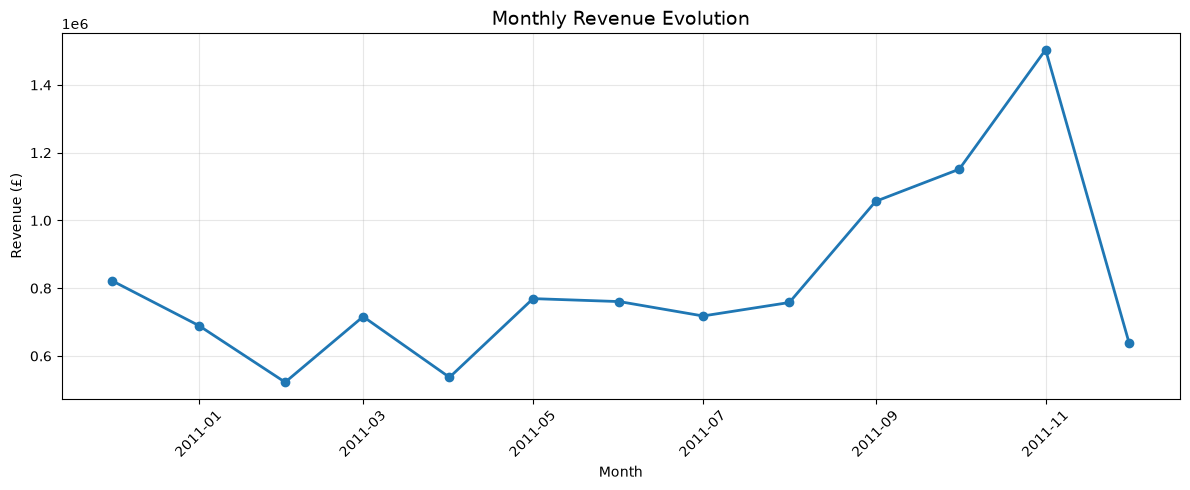

In [21]:

plt.figure(figsize=(12, 5))

plt.plot(
    mom_df["sales_month"],
    mom_df["revenue"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Revenue Evolution", fontsize=14)
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


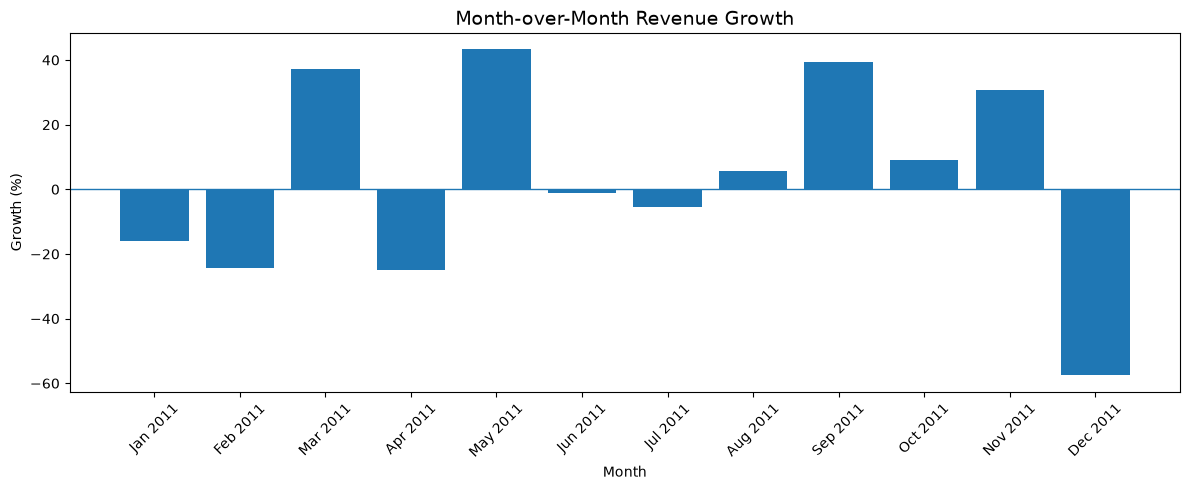

In [22]:

plt.figure(figsize=(12, 5))

plt.bar(
    mom_df["sales_month"].dt.strftime("%b %Y"),
    mom_df["month_over_month_pct"]
)

plt.axhline(y=0, linewidth=1)

plt.title("Month-over-Month Revenue Growth", fontsize=14)
plt.xlabel("Month")
plt.ylabel("Growth (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


In [30]:
query_dim= """
CREATE OR REPLACE VIEW public.dim_product AS
WITH description_counts AS (
    SELECT
        TRIM(stockcode) AS stockcode,
        description,
        COUNT(*) AS occurrences
    FROM public.retail_sales
    WHERE TRIM(stockcode) ~ '^[0-9]{5}[A-Za-z]?$'
      AND description IS NOT NULL
      AND TRIM(description) <> ''
    GROUP BY TRIM(stockcode), description
),
ranked_descriptions AS (
    SELECT
        stockcode,
        description,
        occurrences,
        ROW_NUMBER() OVER (
            PARTITION BY stockcode
            ORDER BY occurrences DESC, description ASC
        ) AS rn
    FROM description_counts
)
SELECT
    stockcode,
    description AS product_name
FROM ranked_descriptions
WHERE rn = 1;
"""

with engine.begin() as connection:
    connection.execute(text(query_dim))

print("Vue dim_product créée avec succès !")

Vue dim_product créée avec succès !


In [31]:
query_check = """
SELECT *
FROM public.dim_product
WHERE stockcode = '23196';
"""

with engine.connect() as connection:
    dim_produit = pd.read_sql_query(text(query_check), connection)

display(dim_produit)

,stockcode,product_name
0,23196,VINTAGE LEAF MAGNETIC NOTEPAD


In [32]:
query_quality = """
SELECT
    COUNT(*) AS total_products,
    COUNT(DISTINCT stockcode) AS unique_products,
    COUNT(*) - COUNT(DISTINCT stockcode) AS duplicates
FROM public.dim_product;
"""

with engine.connect() as connection:
    quality_df = pd.read_sql_query(text(query_quality), connection)

display(quality_df)

,total_products,unique_products,duplicates
0,3898,3898,0
